# 4. An eclipsing binary star: an Algol-like system

Binaries need nothing new in `System3D`: two stars are two bodies, their coronae are volumes, and `KeplerOrbit` places them at each orbital phase. A System3D renders one epoch, so an orbit is simply a loop over phases.

Here we model a system on Algol (β Per; approximate parameters, e.g. Baron et al. 2012): a B8 dwarf (A: 3.2 M☉, 2.7 R☉), X-ray dark, and a K subgiant (B: 0.7 M☉, ~3.5 R☉) that fills its Roche lobe and has a hot corona; P = 2.87 d (so a = 13.3 R☉ by Kepler's law), i ≈ 99°, d = 28.5 pc. At that distance 1 R☉ is 163 µas, so the orbit is ~2 mas across and B's corona ~2 mas, which an X-ray interferometer resolves. We give B 99% of its Roche lobe's volume-equivalent radius (3.40 R☉).

* **B**: a `RocheLobe` body, corotating, with a `Shell` corona (n² emission, steep density profile) and one coronal `Loop`;
* **A**: an opaque `Sphere` that eclipses B's corona around phase 0.5 and reflects a little of it (B's corona as an *extended illuminator*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

import xrimodel as xm
from xrimodel.engine import KeplerOrbit, Lamp, Loop, RocheLobe, Scene, Shell, Sphere, System3D
from xrimodel.units import UAS_PER_RAD

try:   # a 2 keV bremsstrahlung through XSPEC models, else a blackbody stand-in
    from xrimodel.adapters.xspec import xspec_spectrum  # noqa: F401
    corona_spec = {"kind": "xspec", "model": "C_bremss", "params": [2.0], "norm": 1.0}
except ImportError:
    corona_spec = {"kind": "blackbody", "kt": 1.0, "norm": 1.0}

M_A, M_B, R_A, R_B, P = 3.17, 0.70, 2.73, 3.40, 2.867   # R_B: 99% of its Roche lobe
orb = KeplerOrbit(m1=M_A, m2=M_B, period_days=P, omega=-90.0, length_unit="Rsun")
print(f"a = {orb.a:.1f} Rsun")
omega = 2 * np.pi / (P * 86400)


def algol(phase, illuminate=False):
    s = orb.state(phase)
    rA, rB, vA, vB = (tuple(map(float, s[k])) for k in ("r1", "r2", "v1", "v2"))
    th = np.degrees(np.arctan2(rB[1] - rA[1], rB[0] - rA[0]))   # line of centres
    corot = {"omega": omega, "axis": (0.0, 0.0, 1.0), "centre": (0.0, 0.0, 0.0)}
    A = Sphere(name="A", centre=rA, radius=R_A, velocity=vA, albedo=0.3, reflection="grey",
               rotation={"omega": omega})
    B = RocheLobe(name="B", centre=rB, companion=rA, q=M_A / M_B, r_eq=R_B, cm=(0.0, 0.0, 0.0),
                  rotation=corot, reflection=None)
    corona = Shell(name="corona", centre=rB, r_in=3.0, r_out=7.0, n0=1e10, index=3.0,
                   absorption="none", scatter=0.0, velocity=vB, n_fine=256,
                   emission={"spectrum": corona_spec, "j0": 1.0, "power": 2,
                             "illuminates": illuminate, "n_points": 16})
    # a loop fixed on B's surface (synchronous rotation: fixed relative to the line of centres)
    loop = Loop(name="loop", star=rB, r_star=R_B, foot1=(25.0, th + 150.0),
                foot2=(40.0, th + 175.0), height=1.2, thickness=0.12, n0=3e10,
                rotation={"omega": omega}, velocity=vB, n_fine=1024,
                emission={"spectrum": corona_spec, "j0": 1.0, "power": 2})
    return System3D(name="algol", length_unit="Rsun", inclination=98.7, node_pa=40.0,
                    bodies=[A, B], volumes=[corona, loop], chunk=2048)


def render(phase, grid, **kw):
    sc = Scene(ra=47.0422, dec=40.9556, distance_pc=28.5, grid=grid)
    sc.add(algol(phase, **kw))
    return sc.render()

a = 13.3 Rsun


## The X-ray light curve

Here we show the total flux and the flux-weighted line-of-sight velocity of B's corona around the orbit (phase 0: B in front of A). The X-ray eclipse is at phase 0.5, when A passes in front of B's corona, and it is partial because the corona extends beyond A's disc. The shallow dips at quadrature are the coronal analogue of ellipsoidal variation: seen broadside, B's elongated Roche lobe hides more of the corona behind it. The velocity curve has B's semi-amplitude, K_B = 2π a_B sin i / P ≈ 200 km/s.

(The rays' extent defaults to the scene's bounds. Only set `extent` by hand to enlarge it, otherwise parts of the scene are cut off.)

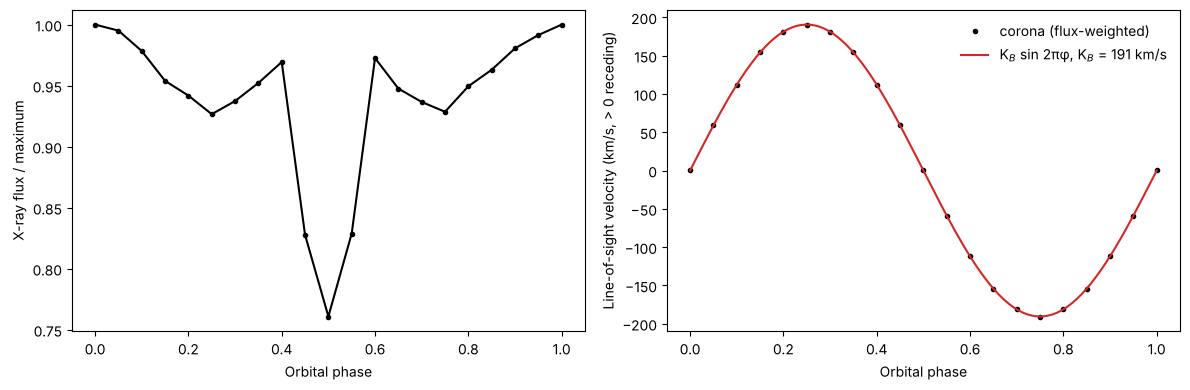

In [2]:
coarse = xm.RegularGrid(nx=66, ny=66, scale=100.0)         # 0.1 mas pixels, 6.6 mas across
phases = np.linspace(0.0, 1.0, 21)
flux, vel = [], []
for ph in phases:
    m = render(ph, coarse)
    flux.append(sum(L.mean_photon_flux() for L in m.layers))
    cor = [L for L in m.layers if L.name.startswith("algol_corona")]
    w = sum(L.maps["NORM"].sum() for L in cor)
    vel.append((1 - sum((L.maps["NORM"] * L.maps["G"]).sum() for L in cor) / w) * 2.998e5)
flux, vel = np.array(flux), np.array(vel)

a_B = orb.a * M_A / (M_A + M_B) * 6.957e5   # km
K_B = 2 * np.pi * a_B * np.sin(np.deg2rad(98.7)) / (P * 86400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(phases, flux / flux.max(), "ko-", ms=3)
ax[0].set_xlabel("Orbital phase"); ax[0].set_ylabel("X-ray flux / maximum")
ax[1].plot(phases, vel, "ko", ms=3, label="corona (flux-weighted)")
ph_f = np.linspace(0, 1, 200)
ax[1].plot(ph_f, K_B * np.sin(2 * np.pi * ph_f), "C3", label=f"K$_B$ sin 2πφ, K$_B$ = {K_B:.0f} km/s")
ax[1].set_xlabel("Orbital phase"); ax[1].set_ylabel("Line-of-sight velocity (km/s, > 0 receding)")
ax[1].legend(frameon=False)
fig.tight_layout()

The sign of the curve follows from the geometry: just after phase 0, B (in front) moves away from us.

## Images around the eclipse

Here we show B's corona at quadrature and during the eclipse; the dashed circle is A's limb and the cross the centre of mass. The optically thin corona is limb-brightened, since the line of sight through it is longest just outside B's surface. At ingress A's limb cuts across the corona, and at mid-eclipse A hides B's disc and the corona in front of it, leaving the rest of the corona visible.

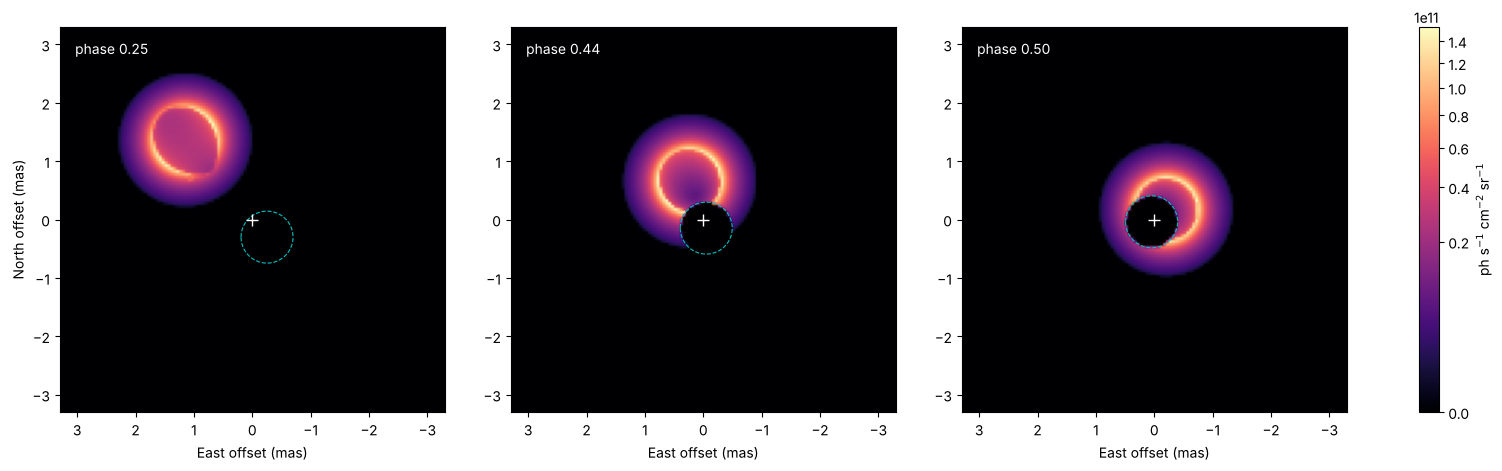

In [3]:
grid = xm.RegularGrid(nx=132, ny=132, scale=50.0)          # 50 uas pixels, 6.6 mas across
show = (0.25, 0.44, 0.5)
imgs = {}
for ph in show:
    m = render(ph, grid)
    tot = sum(L.maps["NORM"] for L in m.layers)
    imgs[ph] = grid.to_image(tot) / (grid.scale / UAS_PER_RAD) ** 2

uas_per_rsun = 6.957e10 / (28.5 * 3.0857e18) * UAS_PER_RAD
h = grid.nx / 2 * grid.scale / 1e3
vmax = max(i.max() for i in imgs.values())
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for a, ph in zip(ax, show):
    im = a.imshow(imgs[ph], origin="lower", extent=[h, -h, -h, h], cmap="magma",
                  norm=PowerNorm(0.4, vmin=0, vmax=vmax))
    # A's limb on the sky
    sysm = algol(ph)
    rA = np.asarray(orb.state(ph)["r1"])
    fr = sysm.frame()
    u_a, u_b = sysm.sky_axes()
    sky = (rA @ fr["e_a"]) * u_a + (rA @ fr["e_b"]) * u_b
    t = np.linspace(0, 2 * np.pi, 200)
    a.plot((sky[0] + R_A * np.cos(t)) * uas_per_rsun / 1e3, (sky[1] + R_A * np.sin(t)) * uas_per_rsun / 1e3,
           "c--", lw=0.8)
    a.plot(0, 0, "+", color="w", ms=8)
    a.text(0.04, 0.93, f"phase {ph:.2f}", transform=a.transAxes, color="w")
    a.set_xlabel("East offset (mas)")
ax[0].set_ylabel("North offset (mas)")
fig.colorbar(im, ax=ax, label="ph s$^{-1}$ cm$^{-2}$ sr$^{-1}$", fraction=0.02)

## B's corona lights A

With `emission["illuminates"]` the corona also acts as an illuminator, represented by 16 seeded points drawn from its emissivity, and A's surface reflects it (grey albedo 0.3). The reflected light is faint, but shows where A faces the corona.

algol_corona_emit0 2.333e-06 (relative units)
algol_loop_emit0 2.812e-09 (relative units)
algol_A        7.843e-09 (relative units)


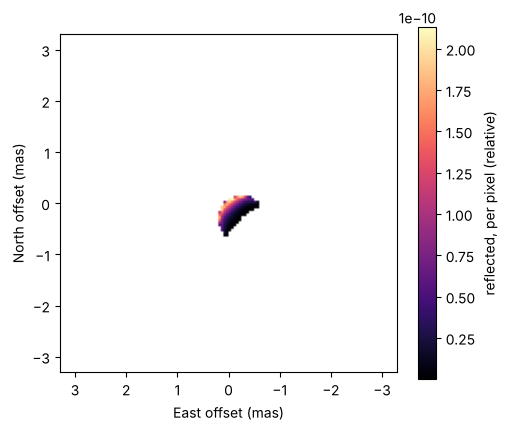

In [4]:
m = render(0.25, grid, illuminate=True)
for L in m.layers:
    print(f"{L.name:14s} {L.mean_photon_flux():.3e} (relative units)")
refl = grid.to_image(m.layer("algol_A").maps["NORM"])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(np.where(refl > 0, refl, np.nan), origin="lower", extent=[h, -h, -h, h],
               cmap="magma")
fig.colorbar(im, ax=ax, label="reflected, per pixel (relative)")
ax.set_xlabel("East offset (mas)"); ax.set_ylabel("North offset (mas)")
fig.tight_layout()

## Through XRISALIS

Now we take the same model through the interferometer at quadrature and at eclipse ingress, scaled to a total of 0.03 photons/s/cm² at quadrature (Algol's X-ray flux is of that order) and observed for 5 ks at each phase. These use `xri_helpers.observe` (see the quickstart). Needs XRISALIS.

phase 0.25: 164956 events


phase 0.44: 153483 events


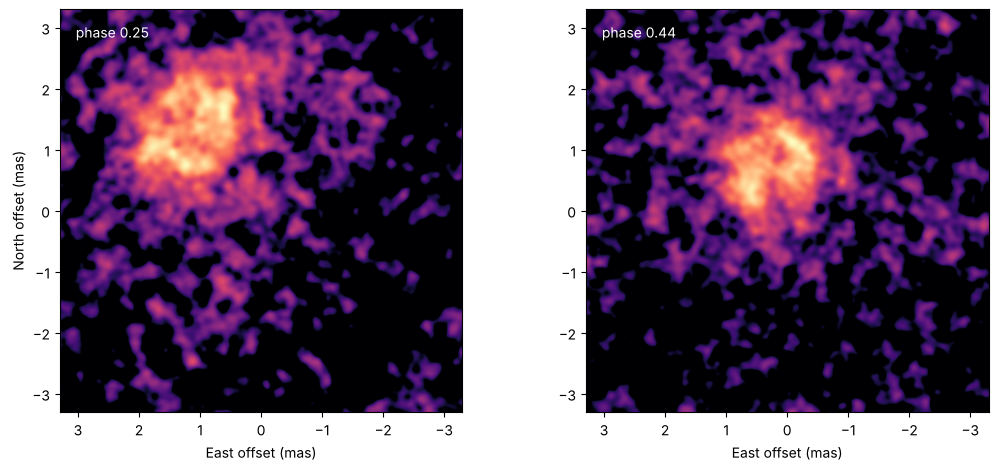

In [5]:
try:
    import xri_helpers as xri
except ImportError as err:   # XRISALIS not installed
    xri = None
    print("skipping:", err)

if xri is not None:
    models = {ph: render(ph, grid) for ph in (0.25, 0.44)}
    flux = {ph: sum(L.mean_photon_flux() for L in m.layers) for ph, m in models.items()}
    recon = {}
    for ph, m in models.items():   # one scale for both phases, so the eclipse dims the image
        recon[ph] = xri.observe(m, 5000.0, fov_arcsec=0.0066, total_flux=0.03 * flux[ph] / flux[0.25],
                                seed=int(100 * ph))
        print(f"phase {ph}: {len(recon[ph]['events'])} events")

    fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
    for a, ph in zip(ax, recon):
        xri.show(a, recon[ph], unit=1e3, gamma=0.6, label=f"phase {ph:.2f}")
    ax[0].set_ylabel("North offset (mas)")

The reconstruction shows B's extended corona and, at ingress, the corona cut by A's limb: eclipse mapping and imaging of the same structure.

**Not modelled here:** the corona's own rotation (only B's orbital velocity is applied to it), optically thick coronal emission, and the stars' optical light, which does not matter for X-rays.